# Network Anomaly Detection — Improved Evaluation (CICIDS2017)

This notebook improves the original Isolation Forest project. It reuses your saved `cleaned_data.parquet` from Google Drive, so run it in Colab with the same Drive folder.

**What changed compared with the original notebook**
1. **Clean train / validation / test split.** The original tested on the same normal flows it trained on. Here, test flows are never seen in training.
2. **Threshold chosen on a validation set** instead of a fixed `contamination=0.17`. Threshold-free metrics (ROC-AUC, PR-AUC) are also reported.
3. **Feature cleanup**: constant and highly correlated features are removed (fit on training data only).
4. **Model comparison**: Isolation Forest vs. an autoencoder (both trained on normal traffic only), plus a supervised Random Forest as a reference upper bound.
5. **Per-attack-type recall**, so you can see which attacks are caught or missed.

Run all cells from top to bottom. The last cell prints the numbers to use on your resume.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, warnings, time
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
DATA_DIR = '/content/drive/MyDrive/CICIDS2017'
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


## 1. Load the cleaned data

In [2]:
df = pd.read_parquet(f'{DATA_DIR}/cleaned_data.parquet')
df.columns = df.columns.str.strip()
df['Label_binary'] = (df['Label'] != 'BENIGN').astype(int)
print('Shape:', df.shape)
print(df['Label_binary'].value_counts().rename({0: 'Normal', 1: 'Attack'}))

Shape: (2520798, 80)
Label_binary
Normal    2095057
Attack     425741
Name: count, dtype: int64


## 2. Split the data (no overlap between train, validation and test)

- **Normal traffic:** 60% train, 15% validation, 25% test.
- **Attack traffic:** 40% train (used only by the supervised reference model), 10% validation, 50% test.
- The two unsupervised models train on **normal train only** and never see attacks.

In [3]:
y = df['Label_binary'].values
labels = df['Label'].values
idx_normal = np.where(y == 0)[0]
idx_attack = np.where(y == 1)[0]

# Normal: 60 / 15 / 25
n_train, n_rest = train_test_split(idx_normal, train_size=0.60, random_state=RANDOM_STATE)
n_val, n_test = train_test_split(n_rest, train_size=0.15 / 0.40, random_state=RANDOM_STATE)

# Attack: 40 / 10 / 50, stratified by attack type
a_train, a_rest = train_test_split(idx_attack, train_size=0.40, random_state=RANDOM_STATE,
                                   stratify=labels[idx_attack])
a_val, a_test = train_test_split(a_rest, train_size=0.10 / 0.60, random_state=RANDOM_STATE,
                                 stratify=labels[a_rest])

idx_val = np.concatenate([n_val, a_val])
idx_test = np.concatenate([n_test, a_test])
y_val, y_test = y[idx_val], y[idx_test]
print(f'Normal train {len(n_train):,} | val {len(n_val):,} | test {len(n_test):,}')
print(f'Attack train {len(a_train):,} | val {len(a_val):,} | test {len(a_test):,}')
print(f'Test set is {y_test.mean():.1%} attacks')

Normal train 1,257,034 | val 314,258 | test 523,765
Attack train 170,296 | val 42,574 | test 212,871
Test set is 28.9% attacks


## 3. Feature cleanup (fit on normal training data only)

In [4]:
feature_cols = [c for c in df.columns if c not in ('Label', 'Label_binary')]
X_all = df[feature_cols].values.astype(np.float32)

# 3a. Drop constant / near-constant features
train_var = X_all[n_train].var(axis=0)
keep = [c for c, v in zip(feature_cols, train_var) if v > 1e-8]
print(f'Dropped {len(feature_cols) - len(keep)} constant features')

# 3b. Drop one of each highly correlated pair (|r| > 0.95), using a normal-train sample
rng = np.random.RandomState(RANDOM_STATE)
sample = rng.choice(n_train, size=min(200_000, len(n_train)), replace=False)
corr = pd.DataFrame(df.loc[sample, keep].values, columns=keep).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_corr = [c for c in upper.columns if (upper[c] > 0.95).any()]
final_cols = [c for c in keep if c not in drop_corr]
print(f'Dropped {len(drop_corr)} highly correlated features')
print(f'Features: {len(feature_cols)} -> {len(final_cols)}')

# 3c. Scale (fit on normal train only) and clip extreme values so a few outliers do not dominate
X = df[final_cols].values.astype(np.float32)
scaler = StandardScaler().fit(X[n_train])
X = np.clip(scaler.transform(X), -10, 10).astype(np.float32)
X_train, X_val, X_test = X[n_train], X[idx_val], X[idx_test]
print('Ready:', X_train.shape, X_val.shape, X_test.shape)

Dropped 8 constant features
Dropped 27 highly correlated features
Features: 78 -> 43
Ready: (1257034, 43) (356832, 43) (736636, 43)


## 4. Evaluation helper

The decision threshold is picked on the **validation set** (best F1). Test-set results are then reported once, without further tuning. ROC-AUC and PR-AUC do not depend on any threshold.

In [5]:
def pick_threshold(y_true, scores):
    p, r, t = precision_recall_curve(y_true, scores)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return t[np.argmax(f1)]

def report(name, s_val, s_test, threshold=None):
    thr = pick_threshold(y_val, s_val) if threshold is None else threshold
    pred = (s_test >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    fpr, tpr, _ = roc_curve(y_test, s_test)
    return {'Model': name,
            'ROC-AUC': roc_auc_score(y_test, s_test),
            'PR-AUC': average_precision_score(y_test, s_test),
            'Precision': prec, 'Recall': rec,
            'F1': 2 * prec * rec / max(prec + rec, 1e-12),
            'Accuracy': (tp + tn) / len(y_test),
            'False alarm rate': fp / max(fp + tn, 1),
            'Recall @5% FPR': np.interp(0.05, fpr, tpr),
            '_pred': pred, '_scores': s_test}

## 5. Model 1 — Isolation Forest (normal traffic only)

In [6]:
t0 = time.time()
iso = IsolationForest(n_estimators=200, max_samples=256, random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_train)
# Higher score = more anomalous
iso_val, iso_test = -iso.score_samples(X_val), -iso.score_samples(X_test)
iso_train_scores = -iso.score_samples(X_train[:200_000])
print(f'Isolation Forest trained and scored in {time.time() - t0:.0f}s')

results = []
# Original-style threshold: flag the top 17% most anomalous flows, like contamination=0.17
orig_thr = np.percentile(iso_train_scores, 83)
results.append(report('Isolation Forest (original-style threshold)', iso_val, iso_test, threshold=orig_thr))
results.append(report('Isolation Forest (validation-tuned threshold)', iso_val, iso_test))
pd.DataFrame(results).drop(columns=['_pred', '_scores']).round(3)

Isolation Forest trained and scored in 17s


,Model,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,False alarm rate,Recall @5% FPR
0,Isolation Forest (original-style threshold),0.8,0.665,0.592,0.602,0.597,0.765,0.169,0.442
1,Isolation Forest (validation-tuned threshold),0.8,0.665,0.780,0.569,0.658,0.829,0.065,0.442


## 6. Model 2 — Autoencoder (normal traffic only)

A small neural network learns to reconstruct normal traffic. Attacks reconstruct poorly, so a large reconstruction error signals an anomaly. This uses scikit-learn's `MLPRegressor`, so no extra installs are needed.

In [7]:
t0 = time.time()
rng = np.random.RandomState(RANDOM_STATE)
ae_idx = rng.choice(len(X_train), size=min(300_000, len(X_train)), replace=False)
n_feat = X_train.shape[1]
ae = MLPRegressor(hidden_layer_sizes=(max(n_feat // 2, 8), max(n_feat // 4, 4), max(n_feat // 2, 8)),
                  activation='relu', solver='adam', batch_size=512, max_iter=40,
                  early_stopping=True, n_iter_no_change=4, random_state=RANDOM_STATE)
ae.fit(X_train[ae_idx], X_train[ae_idx])

def recon_error(M, chunk=200_000):
    out = np.empty(len(M), dtype=np.float32)
    for i in range(0, len(M), chunk):
        part = M[i:i + chunk]
        out[i:i + chunk] = ((part - ae.predict(part)) ** 2).mean(axis=1)
    return out

ae_val, ae_test = recon_error(X_val), recon_error(X_test)
print(f'Autoencoder trained and scored in {time.time() - t0:.0f}s')
results.append(report('Autoencoder', ae_val, ae_test))

Autoencoder trained and scored in 37s


## 7. Reference — supervised Random Forest

This model **does** see labeled attacks during training, so it is not a fair comparison for the unsupervised models. It shows the upper bound you could reach if labeled attack data were available.

In [8]:
t0 = time.time()
rng = np.random.RandomState(RANDOM_STATE)
rf_normal = rng.choice(n_train, size=min(300_000, len(n_train)), replace=False)
rf_idx = np.concatenate([rf_normal, a_train])
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE, class_weight='balanced')
rf.fit(X[rf_idx], y[rf_idx])
rf_val, rf_test = rf.predict_proba(X_val)[:, 1], rf.predict_proba(X_test)[:, 1]
print(f'Random Forest trained and scored in {time.time() - t0:.0f}s')
results.append(report('Random Forest (supervised reference)', rf_val, rf_test))

Random Forest trained and scored in 152s


## 8. Model comparison

,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy,False alarm rate,Recall @5% FPR
Model,,,,,,,,
Isolation Forest (original-style threshold),0.800,0.665,0.592,0.602,0.597,0.765,0.169,0.442
Isolation Forest (validation-tuned threshold),0.800,0.665,0.780,0.569,0.658,0.829,0.065,0.442
Autoencoder,0.881,0.801,0.946,0.540,0.687,0.858,0.012,0.595
Random Forest (supervised reference),1.000,0.999,0.998,0.996,0.997,0.998,0.001,1.000


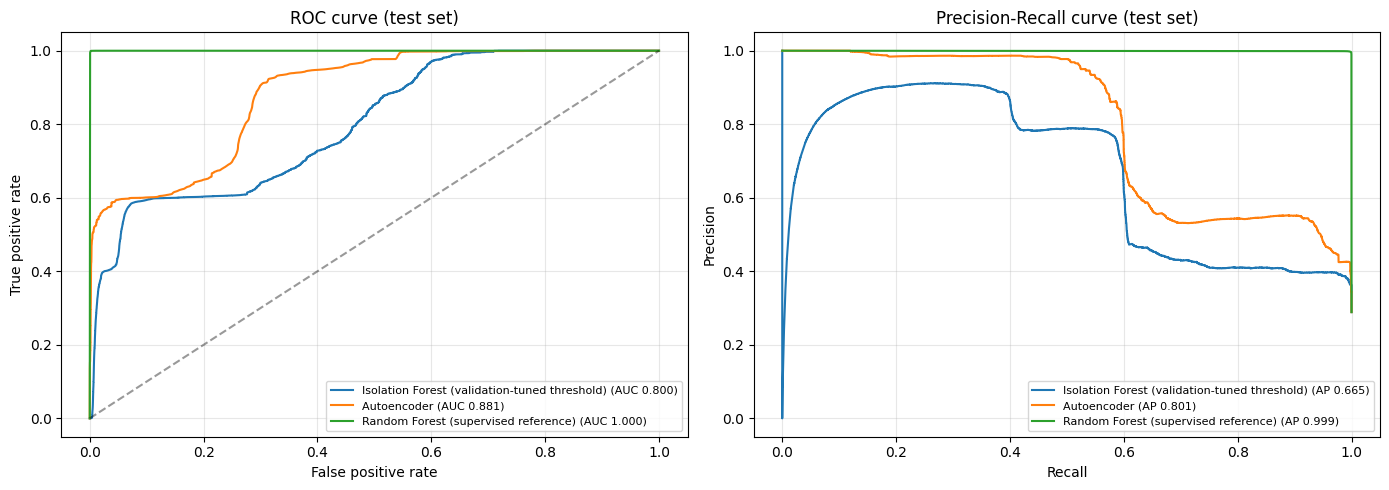

In [9]:
table = pd.DataFrame(results).drop(columns=['_pred', '_scores']).set_index('Model')
display(table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
curve_models = [r for r in results if 'original-style' not in r['Model']]
for r in curve_models:
    fpr, tpr, _ = roc_curve(y_test, r['_scores'])
    axes[0].plot(fpr, tpr, label=f"{r['Model']} (AUC {r['ROC-AUC']:.3f})")
    p, rc, _ = precision_recall_curve(y_test, r['_scores'])
    axes[1].plot(rc, p, label=f"{r['Model']} (AP {r['PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[0].set(title='ROC curve (test set)', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Precision-Recall curve (test set)', xlabel='Recall', ylabel='Precision')
for a in axes: a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f'{DATA_DIR}/model_comparison.png', dpi=150); plt.show()

## 9. Which attacks are caught? (best unsupervised model)

Best unsupervised model by F1: Autoencoder


,Attack type,Flows in test set,Detected,Recall
0,Heartbleed,5,5,1.000
1,DoS Slowhttptest,2614,2331,0.892
2,DoS Hulk,86423,73464,0.850
3,Infiltration,18,10,0.556
4,DDoS,64007,35552,0.555
5,DoS GoldenEye,5143,2453,0.477
6,DoS slowloris,2693,1049,0.390
7,Web Attack � XSS,326,9,0.028
8,Bot,974,17,0.017
9,Web Attack � Brute Force,735,3,0.004


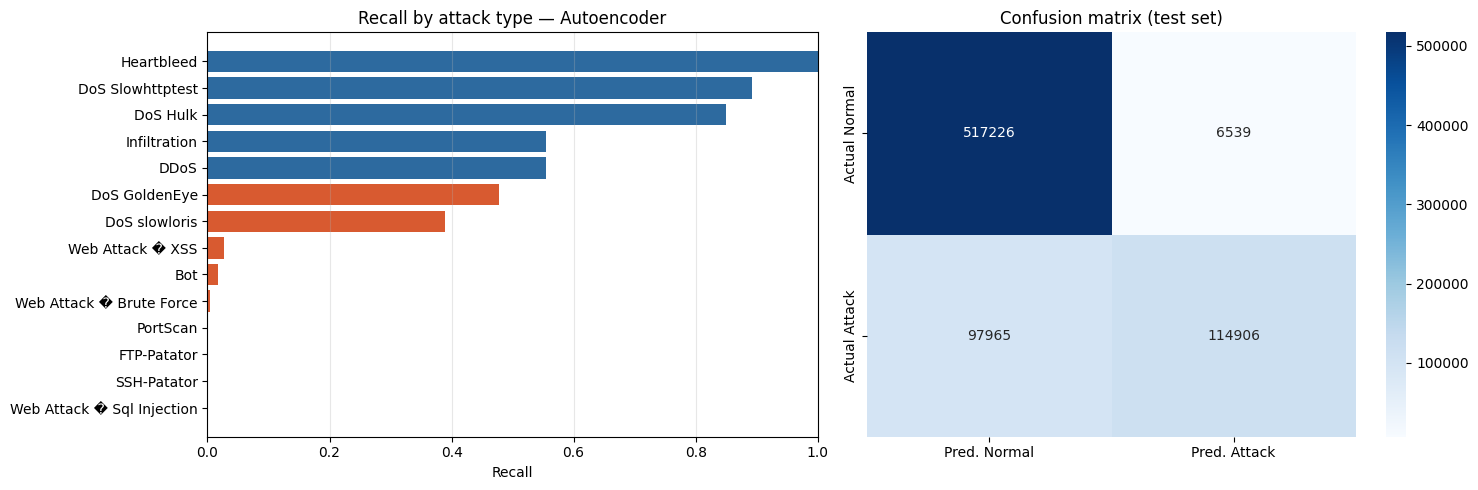

In [10]:
unsup = [r for r in results if 'Autoencoder' in r['Model'] or 'validation-tuned' in r['Model']]
best = max(unsup, key=lambda r: r['F1'])
print('Best unsupervised model by F1:', best['Model'])

test_labels = labels[idx_test]
rows = []
for lab in np.unique(test_labels[y_test == 1]):
    m = test_labels == lab
    rows.append({'Attack type': lab, 'Flows in test set': int(m.sum()),
                 'Detected': int(best['_pred'][m].sum()),
                 'Recall': best['_pred'][m].mean()})
per_attack = pd.DataFrame(rows).sort_values('Recall', ascending=False).reset_index(drop=True)
display(per_attack.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = ['#2d6a9f' if r >= 0.5 else '#d85a30' for r in per_attack['Recall']]
axes[0].barh(per_attack['Attack type'][::-1], per_attack['Recall'][::-1], color=colors[::-1])
axes[0].set(title=f"Recall by attack type — {best['Model']}", xlabel='Recall', xlim=(0, 1))
axes[0].grid(alpha=0.3, axis='x')
cm = confusion_matrix(y_test, best['_pred'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Pred. Normal', 'Pred. Attack'], yticklabels=['Actual Normal', 'Actual Attack'])
axes[1].set_title('Confusion matrix (test set)')
plt.tight_layout(); plt.savefig(f'{DATA_DIR}/attack_type_recall.png', dpi=150); plt.show()

## 10. Save results and print resume-ready numbers

In [11]:
table.round(4).to_csv(f'{DATA_DIR}/results_summary.csv')
per_attack.round(4).to_csv(f'{DATA_DIR}/per_attack_recall.csv', index=False)
joblib.dump({'iso': iso, 'ae': ae, 'scaler': scaler, 'features': final_cols}, f'{DATA_DIR}/improved_models.pkl')

iso_row = table.loc['Isolation Forest (validation-tuned threshold)']
orig_row = table.loc['Isolation Forest (original-style threshold)']
ae_row = table.loc['Autoencoder']
print('=== COPY THESE NUMBERS BACK TO CLAUDE ===')
print(f"Features: {len(feature_cols)} -> {len(final_cols)}")
print(f"Normal train flows: {len(n_train):,} | test flows: {len(idx_test):,} ({y_test.mean():.0%} attacks)")
print(f"Original-style Isolation Forest: recall {orig_row['Recall']:.2f}, precision {orig_row['Precision']:.2f}, F1 {orig_row['F1']:.2f}")
print(f"Tuned Isolation Forest: ROC-AUC {iso_row['ROC-AUC']:.3f}, PR-AUC {iso_row['PR-AUC']:.3f}, recall {iso_row['Recall']:.2f}, precision {iso_row['Precision']:.2f}, F1 {iso_row['F1']:.2f}")
print(f"Autoencoder: ROC-AUC {ae_row['ROC-AUC']:.3f}, PR-AUC {ae_row['PR-AUC']:.3f}, recall {ae_row['Recall']:.2f}, precision {ae_row['Precision']:.2f}, F1 {ae_row['F1']:.2f}")
print(f"Best unsupervised model: {best['Model']}")
print('Top 3 attack types detected:', ', '.join(per_attack['Attack type'].head(3)))
print('Hardest 3 attack types:', ', '.join(per_attack['Attack type'].tail(3)))

=== COPY THESE NUMBERS BACK TO CLAUDE ===
Features: 78 -> 43
Normal train flows: 1,257,034 | test flows: 736,636 (29% attacks)
Original-style Isolation Forest: recall 0.60, precision 0.59, F1 0.60
Tuned Isolation Forest: ROC-AUC 0.800, PR-AUC 0.665, recall 0.57, precision 0.78, F1 0.66
Autoencoder: ROC-AUC 0.881, PR-AUC 0.801, recall 0.54, precision 0.95, F1 0.69
Best unsupervised model: Autoencoder
Top 3 attack types detected: Heartbleed, DoS Slowhttptest, DoS Hulk
Hardest 3 attack types: FTP-Patator, SSH-Patator, Web Attack � Sql Injection
